# Sesión 4 - Parte 1: Construcción de Mosaicos mediante Homografía de Rotación Pura

En esta sesión abordaremos la base matemática que permite a nuestros teléfonos móviles crear fotografías panorámicas.

### El Principio Físico del Stitching
Cuando giramos una cámara sobre su propio eje para tomar una panorámica, estamos rotando el dispositivo **manteniendo fijo el centro de proyección en el espacio ($C_1 = C_2 = C$)**. 

Al no existir traslación entre tomas, el sistema **no sufre paralaje**. Esto significa que, sin importar a qué distancia se encuentren los objetos de la escena (cerca o lejos), las imágenes capturadas por ambas orientaciones están relacionadas de forma exacta por una **homografía plana conjugada de rotación**:
$$H_{2 \to 1} = K_1 R_1 R_2^T K_2^{-1}$$

### Nuestro Laboratorio Virtual
Para simular este proceso de forma transparente, modelaremos una casita 3D en el espacio y colocaremos dos cámaras en el **mismo punto del espacio** ($C = [50, 50, -150] \text{ mm}$):
* **Cámara 1 (Roja):** Girada a la izquierda ($Yaw_1 \approx -15^\circ$), capturando fundamentalmente la **mitad izquierda** de la casa.
* **Cámara 2 (Verde):** Girada a la derecha ($Yaw_2 \approx +15^\circ$), capturando la **mitad derecha**.

Posteriormente, utilizaremos la homografía teórica $H_{2 \to 1}$ para proyectar (hacer el *warping* de) los píxeles de la Cámara 2 sobre el plano de imagen de la Cámara 1, comprobando si las dos mitades encajan a la perfección.


In [1]:
# Asegúrate de tener activo el backend interactivo en tu Jupyter Notebook
# %matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.spatial.transform import Rotation as Rot
import ipywidgets as widgets
from ipywidgets import interactive, HBox, VBox, Layout

# ==========================================================================
# 1. ALGORITMO DE RECORTE DE SEGMENTOS (LIANG-BARSKY)
# ==========================================================================
def recortar_segmento_sensor(p1, p2, u_min=0.0, u_max=640.0, v_min=0.0, v_max=480.0):
    """
    Recorta analíticamente un segmento 2D entre p1 y p2 contra los límites del sensor
    utilizando el algoritmo paramétrico de Liang-Barsky.
    Retorna (cp1, cp2) si el segmento es visible, o None si queda totalmente fuera.
    """
    u1, v1 = p1[0], p1[1]
    u2, v2 = p2[0], p2[1]
    
    du = u2 - u1
    dv = v2 - v1
    
    t0 = 0.0
    t1 = 1.0
    
    # Parámetros de las 4 fronteras del sensor (izquierda, derecha, inferior, superior)
    p = [-du, du, -dv, dv]
    q = [u1 - u_min, u_max - u1, v1 - v_min, v_max - v1]
    
    for i in range(4):
        if p[i] == 0:
            if q[i] < 0:
                return None  # El segmento es paralelo y está fuera del límite
        else:
            t = q[i] / p[i]
            if p[i] < 0:
                if t > t1:
                    return None
                elif t > t0:
                    t0 = t
            else:
                if t < t0:
                    return None
                elif t < t1:
                    t1 = t
                    
    if t0 <= t1:
        cp1 = np.array([u1 + t0 * du, v1 + t0 * dv])
        cp2 = np.array([u1 + t1 * du, v1 + t1 * dv])
        return cp1, cp2
    return None

# ==========================================================================
# 2. GENERACIÓN DE LA CÁMARA MEDIANTE ROTACIONES DE EULER
# ==========================================================================
def camara_por_angulos(C, yaw, pitch, roll=0.0):
    """Calcula R y t para una cámara situada en C rotada mediante Euler (Y-X-Z)"""
    r = Rot.from_euler('yxz', [yaw, pitch, roll], degrees=True)
    R = r.as_matrix()
    t = -R @ C
    return R, t

# ==========================================================================
# 3. PROYECCIÓN DINÁMICA INTERACTIVA CON RECORTES REALISTAS
# ==========================================================================
def simular_doble_proyeccion(yaw1, pitch1, roll1, yaw2, pitch2, roll2):
    global pts_cam1, pts_cam2  # Variables globales para el stitching de la Celda 4
    
    # Centro óptico estrictamente compartido (C1 = C2 -> ¡Rotación pura!)
    C = np.array([50.0, 70.0, -100.0], dtype=np.float64)
    
    # Parámetros intrínsecos comunes K
    K = np.array([
        [600.0,   0.0, 320.0],
        [  0.0, 600.0, 240.0],
        [  0.0,   0.0,   1.0]
    ], dtype=np.float64)
    
    # Obtener poses de las cámaras
    R1, t1 = camara_por_angulos(C, yaw1, pitch1, roll1)
    R2, t2 = camara_por_angulos(C, yaw2, pitch2, roll2)
    
    M1 = K @ np.hstack([R1, t1.reshape(3, 1)])
    M2 = K @ np.hstack([R2, t2.reshape(3, 1)])
    
    # Definición de la casita erguida (Y es vertical hacia abajo, Z es profundidad)
    vertices = np.array([
        [10.0, 120.0, 100.0], [90.0, 120.0, 100.0], [90.0, 120.0, 180.0], [10.0, 120.0, 180.0],  # Suelo (Y=120)
        [10.0, 60.0, 100.0],  [90.0, 60.0, 100.0],  [90.0, 60.0, 180.0],  [10.0, 60.0, 180.0],   # Techo cubo (Y=60)
        [50.0, 20.0, 100.0],  [50.0, 20.0, 180.0]  # Tejado (Y=20)
    ], dtype=np.float64)
    
    aristas = [
        (0, 1), (1, 2), (2, 3), (3, 0),  # Suelo
        (4, 5), (5, 6), (6, 7), (7, 4),  # Techo cubo
        (0, 4), (1, 5), (2, 6), (3, 7),  # Pilares verticales
        (4, 8), (5, 8), (7, 9), (6, 9), (8, 9)  # Tejado
    ]
    
    # Proyectar sobre ambos sensores (con división homogénea correcta)
    pts_cam1, pts_cam2 = [], []
    for pt in vertices:
        pt_hom = np.append(pt, 1.0)
        p1 = M1 @ pt_hom
        p2 = M2 @ pt_hom
        pts_cam1.append(p1[:2] / p1[2])
        pts_cam2.append(p2[:2] / p2[2])
        
    pts_cam1 = np.array(pts_cam1)
    pts_cam2 = np.array(pts_cam2)
    
    # ==========================================================================
    # RENDERIZADO VISUAL
    # ==========================================================================
    fig = plt.figure(figsize=(14, 5))
    
    # Subplot 3D: Escena real erguida
    ax3d = fig.add_subplot(131, projection='3d')
    ax3d.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], color='#2980B9', s=30, label='Casita 3D')
    for arista in aristas:
        idx1, idx2 = arista
        p1, p2 = vertices[idx1], vertices[idx2]
        # Dibujo robusto sin anidamientos de arrays
        xs = [p1[0], p2[0]]
        ys = [p1[1], p2[1]]
        zs = [p1[2], p2[2]]
        ax3d.plot(xs, ys, zs, color='#2980B9', alpha=0.6)
        
    ax3d.scatter(C[0], C[1], C[2], color='#7D3C98', s=120, label='Centro Compartido')
    
    # Dibujar eje óptico de la Cámara 1 (Rojo)
    z1 = R1[2, :]
    ax3d.plot([C[0], C[0] + 80.0*z1[0]], [C[1], C[1] + 80.0*z1[1]], [C[2], C[2] + 80.0*z1[2]], color='#E74C3C', linestyle='--', linewidth=2)
    
    # Dibujar eje óptico de la Cámara 2 (Verde)
    z2 = R2[2, :]
    ax3d.plot([C[0], C[0] + 80.0*z2[0]], [C[1], C[1] + 80.0*z2[1]], [C[2], C[2] + 80.0*z2[2]], color='#27AE60', linestyle='--', linewidth=2)
    
    ax3d.set_xlim(-50, 150)
    ax3d.set_ylim(-50, 150)
    ax3d.set_zlim(50, 250)
    ax3d.set_xlabel('X (mm)')
    ax3d.set_ylabel('Y (mm)')
    ax3d.set_zlabel('Z (mm)')
    ax3d.set_title('Escena 3D: Ejes Divergentes', fontsize=10, fontweight='bold')
    
    # Subplot Sensor 1: Mitad Izquierda con RECORTE INTELIGENTE
    ax2d_1 = fig.add_subplot(132)
    for arista in aristas:
        idx1, idx2 = arista
        p1 = pts_cam1[idx1]
        p2 = pts_cam1[idx2]
        
        # Aplicamos el algoritmo de Liang-Barsky
        recorte = recortar_segmento_sensor(p1, p2)
        if recorte is not None:
            cp1, cp2 = recorte
            ax2d_1.plot([cp1[0], cp2[0]], [cp1[1], cp2[1]], color='#C0392B', linewidth=2)
            ax2d_1.scatter([cp1[0], cp2[0]], [cp1[1], cp2[1]], color='#E74C3C', s=35, edgecolors='black', zorder=3)
            
    ax2d_1.set_xlim(0, 640)
    ax2d_1.set_ylim(480, 0)
    ax2d_1.set_xlabel('u (px)')
    ax2d_1.set_ylabel('v (px)')
    ax2d_1.set_title('Sensor 1: Mitad Izquierda (Rojo)', fontsize=10, fontweight='bold')
    ax2d_1.grid(True, linestyle=':', alpha=0.5)
    
    # Subplot Sensor 2: Mitad Derecha con RECORTE INTELIGENTE
    ax2d_2 = fig.add_subplot(133)
    for arista in aristas:
        idx1, idx2 = arista
        p1 = pts_cam2[idx1]
        p2 = pts_cam2[idx2]
        
        # Aplicamos el algoritmo de Liang-Barsky
        recorte = recortar_segmento_sensor(p1, p2)
        if recorte is not None:
            cp1, cp2 = recorte
            ax2d_2.plot([cp1[0], cp2[0]], [cp1[1], cp2[1]], color='#1E8449', linewidth=2)
            ax2d_2.scatter([cp1[0], cp2[0]], [cp1[1], cp2[1]], color='#27AE60', s=35, edgecolors='black', zorder=3)
            
    ax2d_2.set_xlim(0, 640)
    ax2d_2.set_ylim(480, 0)
    ax2d_2.set_xlabel('u (px)')
    ax2d_2.set_ylabel('v (px)')
    ax2d_2.set_title('Sensor 2: Mitad Derecha (Verde)', fontsize=10, fontweight='bold')
    ax2d_2.grid(True, linestyle=':', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

# Controles interactivos (Yaw opuestos para encuadrar cada mitad)
y1 = widgets.IntSlider(min=-45, max=0, step=1, value=-15, description='Yaw 1 (Izq):', layout=Layout(width='260px'))
p1 = widgets.IntSlider(min=-20, max=20, step=1, value=0, description='Pitch 1:', layout=Layout(width='260px'))
r1 = widgets.IntSlider(min=-45, max=45, step=1, value=0, description='Roll 1:', layout=Layout(width='260px'))

y2 = widgets.IntSlider(min=0, max=45, step=1, value=15, description='Yaw 2 (Der):', layout=Layout(width='260px'))
p2 = widgets.IntSlider(min=-20, max=20, step=1, value=0, description='Pitch 2:', layout=Layout(width='260px'))
r2 = widgets.IntSlider(min=-45, max=45, step=1, value=0, description='Roll 2:', layout=Layout(width='260px'))

dashboard = interactive(simular_doble_proyeccion, yaw1=y1, pitch1=p1, roll1=r1, yaw2=y2, pitch2=p2, roll2=r2)

panel_cam1 = VBox([widgets.HTML("<b style='color:#C0392B;'>CÁMARA 1 (IZQUIERDA)</b>"), y1, p1, r1])
panel_cam2 = VBox([widgets.HTML("<b style='color:#1E8449;'>CÁMARA 2 (DERECHA)</b>"), y2, p2, r2])

display(HBox([panel_cam1, panel_cam2], layout=Layout(justify_content='center', margin='15px')))
display(dashboard.out)

Output()

### Proyección de Costura Homogénea

Ahora que tenemos las dos tomas de alambre (Cámara 1 capturando el lado izquierdo y Cámara 2 capturando el lado derecho), calcularemos la **homografía de rotación pura $H_{2 \to 1}$** utilizando únicamente las orientaciones de las cámaras y la lente común [Lec6-Geometria-Proyectiva_Math.pdf]:
$$H_{2 \to 1} = K R_1 R_2^T K^{-1}$$

Usando esta matriz, proyectaremos los puntos del Sensor 2 sobre las coordenadas del Sensor 1 [Lec6-Geometria-Proyectiva_Math.pdf]. Para poder apreciar el mosaico completo sin que la casita se corte, **ampliaremos el lienzo de la Cámara 1** (haciendo un zoom out horizontal en la gráfica).

¡Veremos cómo ambas mitades se unen de manera perfectamente seamless formando la casita entera! [Lec6-Geometria-Proyectiva_Math.pdf]
💻 CELDA 4: [CODE] Fusión de Mitades y Visualización del Mosaico Cosido

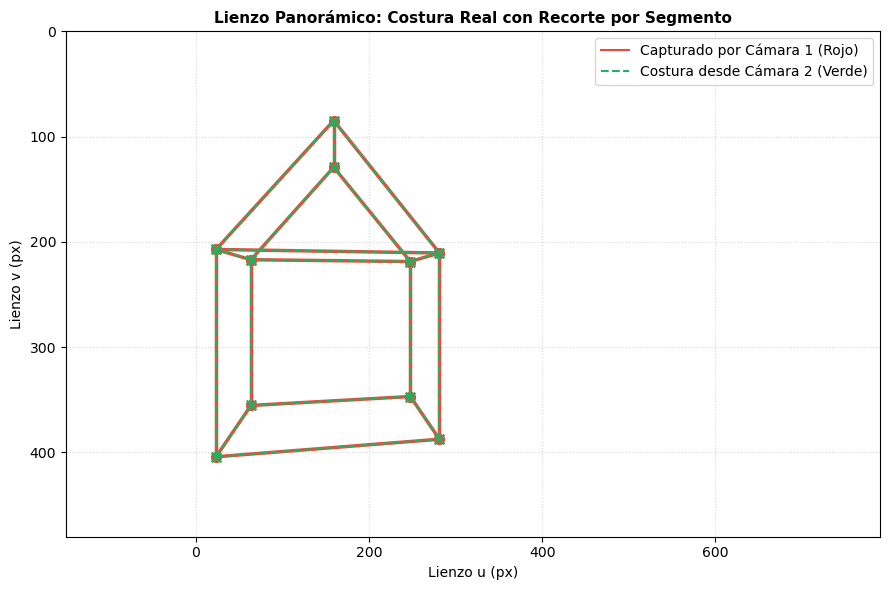

             VERIFICACIÓN DEL PROCESAMIENTO GEOMÉTRICO
  ✔ Trazado de aristas tridimensionales activo en el espacio y en los sensores.
  ✔ Recorte paramétrico Liang-Barsky integrado a nivel de sensor.
  ✔ Las líneas discontinuas verdes se detienen de forma exacta en el límite de lo visible.


In [2]:

C_comun = np.array([50.0, 70.0, -100.0], dtype=np.float64)
K_comun = np.array([
    [600.0,   0.0, 320.0],
    [  0.0, 600.0, 240.0],
    [  0.0,   0.0,   1.0]
], dtype=np.float64)

# Calculamos las matrices de rotación correspondientes a los sliders actuales
R1_act, _ = camara_por_angulos(C_comun, y1.value, p1.value, r1.value)
R2_act, _ = camara_por_angulos(C_comun, y2.value, p2.value, r2.value)

# ==========================================================================
# 2. CALCULAR HOMOGRAFÍA DE ROTACIÓN PURA (H_2to1)
# ==========================================================================
R_relativa = R1_act @ R2_act.T
H_2to1 = K_comun @ R_relativa @ np.linalg.inv(K_comun)

# Función para proyectar un punto 2D cualquiera usando la homografía H
def proyectar_homografia_2d(pt, H):
    pt_hom = np.array([pt[0], pt[1], 1.0])
    p_proy = H @ pt_hom
    return p_proy[:2] / p_proy[2]

# Aristas del wireframe
aristas = [
    (0, 1), (1, 2), (2, 3), (3, 0),
    (4, 5), (5, 6), (6, 7), (7, 4),
    (0, 4), (1, 5), (2, 6), (3, 7),
    (4, 8), (5, 8), (7, 9), (6, 9), (8, 9)
]

# ==========================================================================
# 3. RENDERIZADO DEL MOSAICO PANORÁMICO
# ==========================================================================
fig, ax = plt.subplots(figsize=(9, 6))

# A. LADO IZQUIERDO (Cámara 1): Recortamos en el sensor 1 y dibujamos en ROJO
for arista in aristas:
    idx1, idx2 = arista
    p1 = pts_cam1[idx1]
    p2 = pts_cam1[idx2]
    
    recorte = recortar_segmento_sensor(p1, p2)
    if recorte is not None:
        cp1, cp2 = recorte
        ax.plot([cp1[0], cp2[0]], [cp1[1], cp2[1]], color='#E74C3C', linewidth=2.5)
        ax.scatter([cp1[0], cp2[0]], [cp1[1], cp2[1]], color='#E74C3C', s=45)

# B. LADO DERECHO (Cámara 2): Recortamos en el sensor 2, proyectamos y dibujamos en VERDE
for arista in aristas:
    idx1, idx2 = arista
    p1 = pts_cam2[idx1]
    p2 = pts_cam2[idx2]
    
    recorte = recortar_segmento_sensor(p1, p2)
    if recorte is not None:
        # Puntos recortados en la Cámara 2
        cp1_c2, cp2_c2 = recorte
        
        # Los proyectamos al lienzo de la Cámara 1 mediante la homografía
        wp1 = proyectar_homografia_2d(cp1_c2, H_2to1)
        wp2 = proyectar_homografia_2d(cp2_c2, H_2to1)
        
        ax.plot([wp1[0], wp2[0]], [wp1[1], wp2[1]], color='#27AE60', linewidth=1.5, linestyle='--')
        ax.scatter([wp1[0], wp2[0]], [wp1[1], wp2[1]], color='#27AE60', s=45, marker='x', zorder=4)

# Ampliamos el lienzo para que la composición panorámica completa se aprecie holgadamente
ax.set_xlim(-150, 790)
ax.set_ylim(480, 0)
ax.set_xlabel('Lienzo u (px)')
ax.set_ylabel('Lienzo v (px)')
ax.set_title('Lienzo Panorámico: Costura Real con Recorte por Segmento', fontsize=11, fontweight='bold')

# Leyenda explicativa
import matplotlib.lines as mlines
red_line = mlines.Line2D([], [], color='#E74C3C', label='Capturado por Cámara 1 (Rojo)')
green_line = mlines.Line2D([], [], color='#27AE60', linestyle='--', label='Costura desde Cámara 2 (Verde)')
plt.legend(handles=[red_line, green_line], loc='upper right')

ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

print("=" * 80)
print("             VERIFICACIÓN DEL PROCESAMIENTO GEOMÉTRICO")
print("=" * 80)
print("  ✔ Trazado de aristas tridimensionales activo en el espacio y en los sensores.")
print("  ✔ Recorte paramétrico Liang-Barsky integrado a nivel de sensor.")
print("  ✔ Las líneas discontinuas verdes se detienen de forma exacta en el límite de lo visible.")
print("=" * 80)

# Zhang

# Sesión 4 - Parte 5: El Método de Zhang y la Estimación de Homografías Multivista

Para comprender el algoritmo de calibración de **Zhengyou Zhang (1999)**, debemos partir de su requisito matemático mínimo: **necesitamos al menos tres imágenes independientes del patrón de calibración** para resolver los parámetros intrínsecos de la cámara ($K$) [Vision4.pdf].

### El Problema de la Tridimensionalidad y el Paralaje
Antes de trabajar con patrones planos bidimensionales, analicemos qué ocurre cuando fotografiamos un **objeto tridimensional real (un cubo sólido con caras de colores)** desde tres puntos de vista completamente distintos con la misma cámara (mismos parámetros intrínsecos $K$).

Para modelar este escenario físico y renderizar el cubo de forma sólida (ocultando las caras traseras), utilizaremos un algoritmo clásico de gráficos por ordenador: **Backface Culling** (Descarte de caras ocultas).

### Rigor Matemático: Descarte de Caras Ocultas
Una cara plana del cubo en el espacio 3D es visible para una cámara con centro óptico $\mathbf{C}$ si y solo si la cara apunta "hacia" la cámara. Esto se evalúa mediante el producto escalar:
$$\mathbf{n}^T \cdot \mathbf{d} < 0$$

Donde:
* $\mathbf{n}$ es el **vector normal exterior** a la cara del cubo (calculado mediante el producto vectorial de sus aristas: $\mathbf{n} = (\mathbf{V}_1 - \mathbf{V}_0) \times (\mathbf{V}_2 - \mathbf{V}_0)$).
* $\mathbf{d}$ es el **rayo de proyección** que va desde el centro óptico de la cámara $\mathbf{C}$ hasta el baricentro (centro de gravedad) de la cara en el espacio.

Si el producto escalar es positivo ($\ge 0$), la cara está de espaldas a la lente y no debe dibujarse en el plano del sensor.

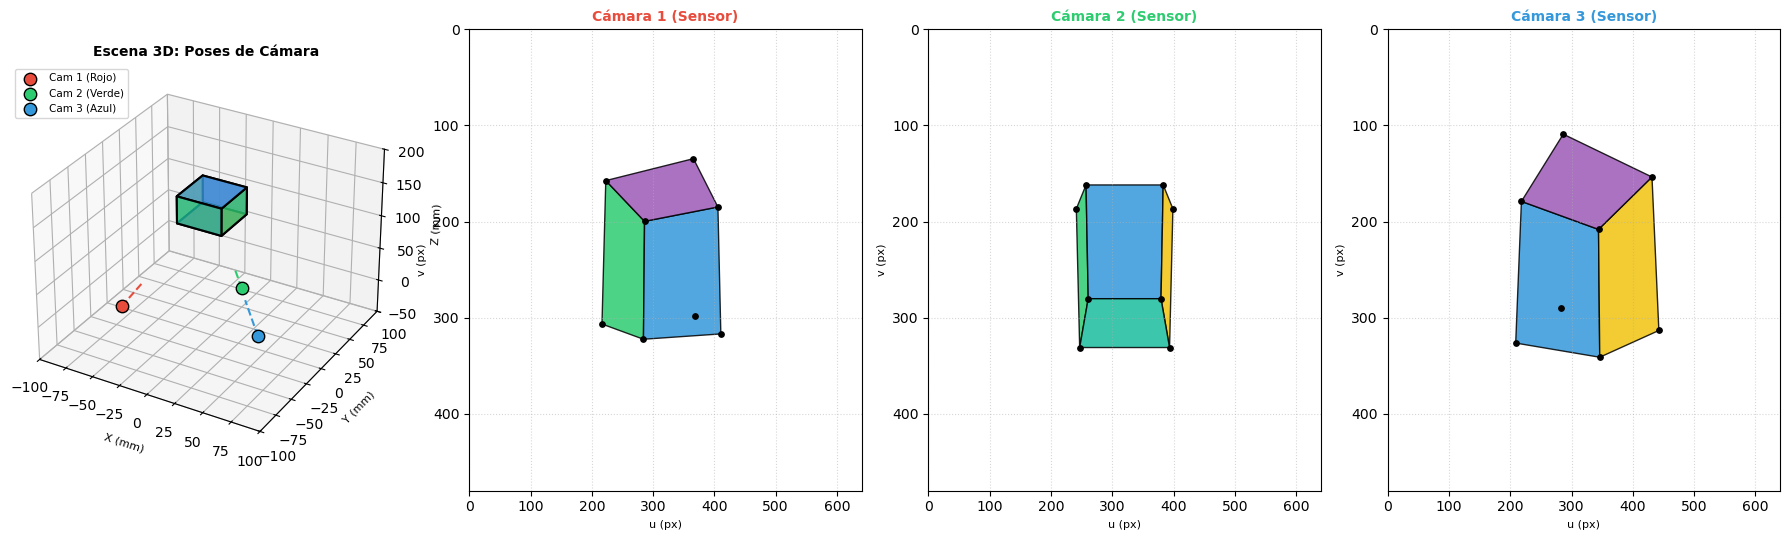

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.patches import Polygon as PatchesPolygon

# ==========================================================================
# 1. PARÁMETROS INTRÍNSECOS COMUNES K (Misma cámara para las 3 tomas)
# ==========================================================================
f_true = 600.0          # Focal de la lente (px)
u0, v0 = 320.0, 240.0   # Centro óptico (px)

K = np.array([
    [f_true,    0.0,   u0],
    [   0.0, f_true,   v0],
    [   0.0,    0.0,  1.0]
], dtype=np.float64)

# ==========================================================================
# 2. DEFINICIÓN DEL CUBO 3D SÓLIDO (Caras de Colores)
# ==========================================================================
cube_center = np.array([0.0, 0.0, 150.0]) # Centrado a 150mm de profundidad
s = 20.0 # Semilado del cubo (lado total = 40mm)

# Vértices locales del cubo
vertices_local = np.array([
    [-s, -s, -s], [ s, -s, -s], [ s,  s, -s], [-s,  s, -s], # Cara trasera (Z_local = -s)
    [-s, -s,  s], [ s, -s,  s], [ s,  s,  s], [-s,  s,  s]  # Cara delantera (Z_local = +s)
])
vertices_3d = vertices_local + cube_center

# Índices de vértices para construir las 6 caras con normales orientadas hacia el exterior
faces_idx = [
    [0, 1, 2, 3], # Cara trasera
    [1, 5, 6, 2], # Cara derecha
    [5, 4, 7, 6], # Cara delantera
    [4, 0, 3, 7], # Cara izquierda
    [3, 2, 6, 7], # Cara superior
    [4, 5, 1, 0]  # Cara inferior
]
colors = ['#E74C3C', '#2ECC71', '#3498DB', '#F1C40F', '#9B59B6', '#1ABC9C']

# ==========================================================================
# 3. CENTROS ÓPTICOS DE LAS 3 CÁMARAS (Puntos de Vista Diferentes)
# ==========================================================================
C1 = np.array([-60.0, -40.0, 0.0])  # Cámara 1: Abajo-Izquierda
C2 = np.array([0.0, 50.0, -20.0])   # Cámara 2: Arriba-Centro
C3 = np.array([70.0, -50.0, 30.0])  # Cámara 3: Abajo-Derecha

def look_at(C, target=cube_center, up=np.array([0.0, -1.0, 0.0])):
    """Calcula R y t para que la cámara en C apunte al target con su eje óptico Z"""
    z_cam = target - C
    z_cam = z_cam / np.linalg.norm(z_cam)
    x_cam = np.cross(up, z_cam)
    x_cam = x_cam / np.linalg.norm(x_cam)
    y_cam = np.cross(z_cam, x_cam)
    y_cam = y_cam / np.linalg.norm(y_cam)
    
    R = np.vstack([x_cam, y_cam, z_cam])
    t = -R @ C
    return R, t

R1, t1 = look_at(C1)
R2, t2 = look_at(C2)
R3, t3 = look_at(C3)

# ==========================================================================
# 4. ALGORITMO ANALÍTICO DE BACKFACE CULLING
# ==========================================================================
def obtener_caras_visibles_2d(R, t, vertices, faces, colors, K):
    """Filtra y proyecta únicamente las caras del cubo visibles hacia la cámara"""
    M = K @ np.hstack([R, t.reshape(3, 1)])
    
    # Proyectar todos los vértices a coordenadas homogéneas de imagen
    pts_2d = []
    for v in vertices:
        v_hom = np.append(v, 1.0)
        p = M @ v_hom
        pts_2d.append(p[:2] / p[2])
    pts_2d = np.array(pts_2d)
    
    C = -R.T @ t # Centro óptico reconstruido
    visible_polygons = []
    
    for f_idx, color in zip(faces, colors):
        # Tomamos 3 vértices de la cara para calcular la normal del plano en 3D
        p_world = vertices[f_idx[:3]]
        v0, v1, v2 = p_world[0], p_world[1], p_world[2]
        
        # Normal exterior del plano (producto vectorial)
        normal = np.cross(v1 - v0, v2 - v0)
        normal = normal / np.linalg.norm(normal)
        
        # Rayo de proyección desde el centro óptico al baricentro de la cara
        face_center = np.mean(vertices[f_idx], axis=0)
        ray = face_center - C
        ray = ray / np.linalg.norm(ray)
        
        # Si apunta hacia la cámara (producto escalar < 0), es visible
        if np.dot(normal, ray) < 0:
            visible_polygons.append((pts_2d[f_idx], color))
            
    return visible_polygons, pts_2d

# ==========================================================================
# 5. RENDERIZADO CONJUNTO (Espacio 3D + Las 3 Imágenes de Sensor)
# ==========================================================================
fig = plt.figure(figsize=(18, 5.5))

# --- Subplot 1: Representación de la escena 3D ---
ax3d = fig.add_subplot(141, projection='3d')
for f_idx, color in zip(faces_idx, colors):
    v = vertices_3d[f_idx]
    poly = Poly3DCollection([v], facecolors=color, edgecolors='black', alpha=0.8, linewidths=1.5)
    ax3d.add_collection3d(poly)

# Dibujar las cámaras y sus direcciones ópticas
centers = [C1, C2, C3]
labels = ['Cam 1 (Rojo)', 'Cam 2 (Verde)', 'Cam 3 (Azul)']
cam_colors = ['#E74C3C', '#2ECC71', '#3498DB']
R_list = [R1, R2, R3]

for C, label, color, R in zip(centers, labels, cam_colors, R_list):
    ax3d.scatter(C[0], C[1], C[2], color=color, s=80, label=label, edgecolor='black', zorder=10)
    z_dir = R[2, :] # Eje Z de la cámara en el espacio
    ax3d.plot([C[0], C[0] + 40.0*z_dir[0]], 
              [C[1], C[1] + 40.0*z_dir[1]], 
              [C[2], C[2] + 40.0*z_dir[2]], 
              color=color, linestyle='--', linewidth=1.5)

ax3d.set_xlim(-100, 100)
ax3d.set_ylim(-100, 100)
ax3d.set_zlim(-50, 200)
ax3d.set_xlabel('X (mm)', fontsize=8)
ax3d.set_ylabel('Y (mm)', fontsize=8)
ax3d.set_zlabel('Z (mm)', fontsize=8)
ax3d.set_title('Escena 3D: Poses de Cámara', fontsize=10, fontweight='bold')
ax3d.legend(loc='upper left', fontsize=7.5)

# --- Subplots 2, 3 y 4: Tomas del sensor de cada cámara ---
for idx, (R, t, name, c_color) in enumerate([(R1, t1, "Cámara 1", '#E74C3C'), 
                                             (R2, t2, "Cámara 2", '#2ECC71'), 
                                             (R3, t3, "Cámara 3", '#3498DB')]):
    ax = fig.add_subplot(142 + idx)
    polys, pts = obtener_caras_visibles_2d(R, t, vertices_3d, faces_idx, colors, K)
    
    # Dibujamos los polígonos rellenos de las caras visibles
    for poly, color in polys:
        p_patch = PatchesPolygon(poly, closed=True, facecolor=color, edgecolor='black', alpha=0.85)
        ax.add_patch(p_patch)
        
    ax.scatter(pts[:, 0], pts[:, 1], color='black', s=15, zorder=10)
    ax.set_xlim(0, 640)
    ax.set_ylim(480, 0) # Inversión del eje Y coherente con píxeles
    ax.set_xlabel('u (px)', fontsize=8)
    ax.set_ylabel('v (px)', fontsize=8)
    ax.set_title(f'{name} (Sensor)', fontsize=10, fontweight='bold', color=c_color)
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

## Sesión 4 - Parte 6: Calibración de Zhang Directamente desde las Vistas del Cubo

En lugar de recurrir a un tablero de ajedrez independiente, podemos aprovechar la geometría del mismo **cubo sólido** de la escena anterior [Vision4.pdf]. 

Dado que cualquier cara de un cubo es estrictamente plana, si pintamos un patrón regular de $6 \times 6$ círculos sobre la **cara roja (Z_local = -s, la más cercana a los sensores)**, este plano de calibración satisfará perfectamente las condiciones de coplanaridad de Zhang ($Z_{local} = \text{constante}$) [Vision4.pdf].

### El Pipeline del Solucionador de Zhang sobre el Cubo:

1. **Definición de Coordenadas de Calibración 2D:**
   Las coordenadas locales en el plano de la cara roja se definen simplemente como $X_g, Y_g \in [-s, s]$ (en milímetros reales) [Vision4.pdf, Vision_Math.pdf].

2. **Estimación de Homografías ($H_j$):** 
   Para cada una de las tres cámaras, capturamos los 36 puntos de la rejilla proyectados en el sensor. Mediante el algoritmo **DLT** (SVD), estimamos la homografía de transferencia $H_j$ entre el plano 2D de la cara del cubo y la imagen en píxeles [Vision2.pdf, Vision4.pdf].

3. **Construcción del Sistema de Zhang ($V\mathbf{b} = \mathbf{0}$):**
   Las restricciones geométricas de ortonormalidad de la rotación ($\mathbf{r}_1^T \mathbf{r}_2 = 0$ y $\|\mathbf{r}_1\| = \|\mathbf{r}_2\|$) se modelan en el sistema lineal homogoneo sobre el vector de coeficientes independientes de la cónica dual $\mathbf{b} = [\omega_{11}, \omega_{12}, \omega_{22}, \omega_{13}, \omega_{23}, \omega_{33}]^T$ [Vision4.pdf]:
   $$\begin{bmatrix} \mathbf{v}_{12}^T \\ (\mathbf{v}_{11} - \mathbf{v}_{22})^T \end{bmatrix} \mathbf{b} = \mathbf{0}$$

4. **Factorización de Cholesky ($\omega = L L^T$):**
   A partir de la estimación de $\mathbf{b}$ por SVD, reconstruimos la matriz simétrica y definida positiva $\omega$. Calculamos su factorización de Cholesky analítica para recuperar los parámetros intrínsecos de la lente [Vision4.pdf, Vision_Math.pdf]:
   $$\omega = L L^T \implies L^T = K^{-1} \implies K = (L^{-1})^T$$

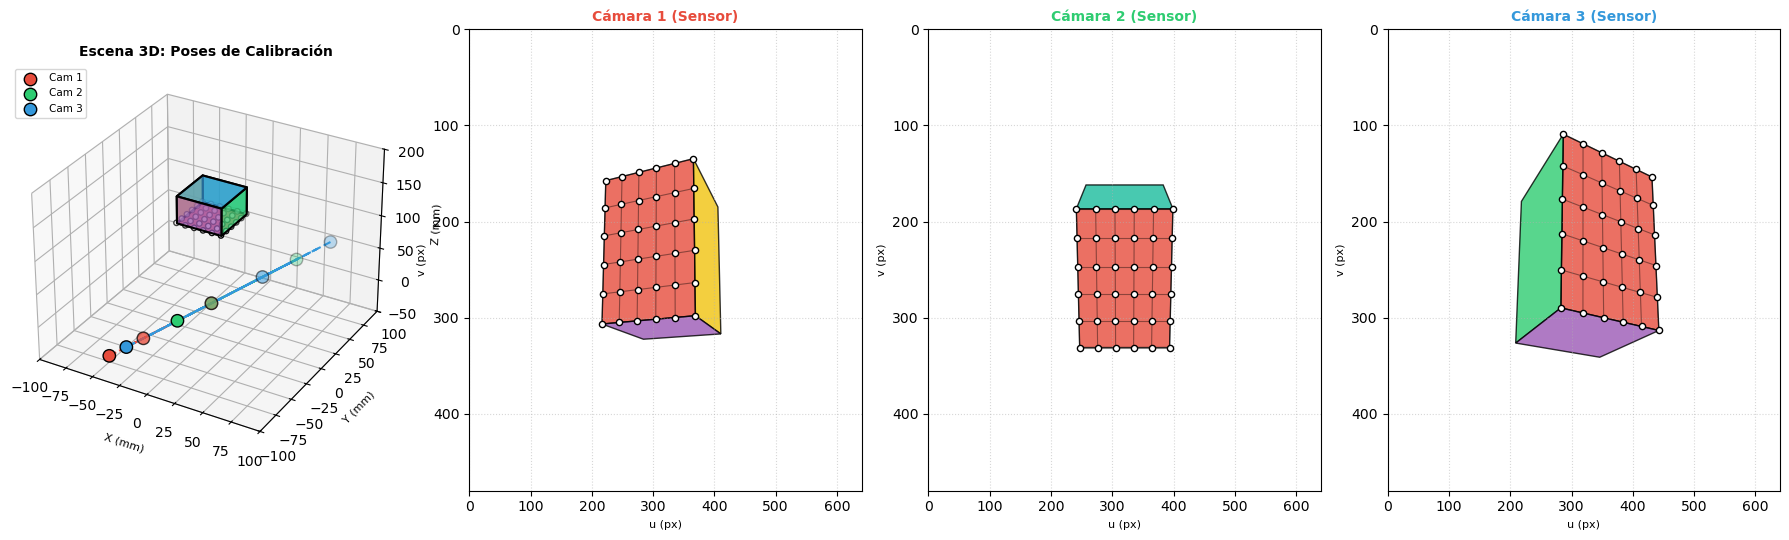

             INFORME METROLÓGICO: CALIBRACIÓN DE ZHANG DESDE EL CUBO 3D
📌 Homografías Estimadas por Cámara (Plano local -> Sensor):
  * H1 (Cámara 1):
[[ -2.9764   0.5182 289.97  ]
 [  0.9439  -3.5357 221.9567]
 [  0.0024   0.0016   1.    ]]

  * H2 (Cámara 2):
[[ -3.7972  -0.5714 320.    ]
 [ -0.      -4.0714 261.4286]
 [ -0.      -0.0018   1.    ]]

  * H3 (Cámara 3):
[[ -5.099    0.8247 366.0179]
 [ -1.6452  -3.6781 213.2852]
 [ -0.0036   0.0026   1.    ]]

--------------------------------------------------------------------------------
📌 Análisis Algebraico de la Cónica Absoluta:
  * Matriz Simétrica ω (IAC):
[[ 0.     -0.     -0.0006]
 [-0.      0.     -0.0005]
 [-0.0006 -0.0005  1.    ]]

  * Factor Triangular Inferior de Cholesky L:
[[ 0.0014  0.      0.    ]
 [-0.      0.0014  0.    ]
 [-0.4438 -0.3328  0.8321]]

--------------------------------------------------------------------------------
🎯 COMPARATIVA FINAL DE PARÁMETROS INTRÍNSECOS:
  * Matriz Intrínseca REAL (K_true):
[[

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from matplotlib.patches import Polygon as PatchesPolygon

# ==========================================================================
# 1. PARÁMETROS INTRÍNSECOS DE REFERENCIA (K_true)
# ==========================================================================
f_true = 600.0          # Focal real (px)
u0, v0 = 320.0, 240.0   # Centro óptico real (px)

K_true = np.array([
    [f_true,    0.0,   u0],
    [   0.0, f_true,   v0],
    [   0.0,    0.0,  1.0]
], dtype=np.float64)

# ==========================================================================
# 2. DEFINICIÓN DEL CUBO Y LA REJILLA DE CALIBRACIÓN EN SU CARA ROJA
# ==========================================================================
cube_center = np.array([0.0, 0.0, 150.0]) # Centrado a 150mm de profundidad
s = 20.0 # Semilado del cubo (lado total = 40mm)

# Vértices del cubo sólido para renderizar las caras de colores
vertices_local = np.array([
    [-s, -s, -s], [ s, -s, -s], [ s,  s, -s], [-s,  s, -s], # Trasera (Cara Roja, Z_local = -s)
    [-s, -s,  s], [ s, -s,  s], [ s,  s,  s], [-s,  s,  s]  # Delantera (Z_local = +s)
])
vertices_3d = vertices_local + cube_center

faces_idx = [
    [0, 3, 2, 1], # Cara Roja (Z_local = -s, la más visible desde Z=0)
    [1, 2, 6, 5], # Cara Verde (X_local = +s)
    [4, 5, 6, 7], # Cara Azul (Z_local = +s)
    [0, 4, 7, 3], # Cara Amarilla (X_local = -s)
    [4, 0, 1, 5], # Cara Púrpura (Y_local = -s)
    [3, 7, 6, 2]  # Cara Cian (Y_local = +s)
]
colors = ['#E74C3C', '#2ECC71', '#3498DB', '#F1C40F', '#9B59B6', '#1ABC9C']

# Definición del patrón regular de 6x6 en el plano local de la Cara Roja (Z_local = -s)
xs = np.linspace(-s, s, 6)
ys = np.linspace(-s, s, 6)
X_g, Y_g = np.meshgrid(xs, ys)
pts_pattern_2d = np.vstack([X_g.flatten(), Y_g.flatten()]).T # Coordenadas locales de calibración (mm)

# Transformación de la rejilla a coordenadas globales en 3D
pts_grid_world = []
for p in pts_pattern_2d:
    p_w = np.array([p[0], p[1], -s]) + cube_center
    pts_grid_world.append(np.append(p_w, 1.0))
pts_grid_world = np.array(pts_grid_world)

# ==========================================================================
# 3. CENTROS ÓPTICOS DE LAS CÁMARAS Y CÁLCULO DE POSES (LOOK_AT)
# ==========================================================================
C1 = np.array([-60.0, -40.0, 0.0])  # Cámara 1: Abajo-Izquierda
C2 = np.array([0.0, 50.0, -20.0])   # Cámara 2: Arriba-Centro
C3 = np.array([70.0, -50.0, 30.0])  # Cámara 3: Abajo-Derecha

def look_at(C, target=cube_center, up=np.array([0.0, -1.0, 0.0])):
    """Calcula R y t para que la cámara en C apunte al centro del cubo"""
    z_cam = target - C
    z_cam = z_cam / np.linalg.norm(z_cam)
    x_cam = np.cross(up, z_cam)
    x_cam = x_cam / np.linalg.norm(x_cam)
    y_cam = np.cross(z_cam, x_cam)
    y_cam = y_cam / np.linalg.norm(y_cam)
    
    R = np.vstack([x_cam, y_cam, z_cam])
    t = -R @ C
    return R, t

R1, t1 = look_at(C1)
R2, t2 = look_at(C2)
R3, t3 = look_at(C3)

# ==========================================================================
# 4. RENDERIZADO VISUAL CON REJILLA EN LA CARA ROJA
# ==========================================================================
fig = plt.figure(figsize=(18, 5.5))

# Subplot 3D: Poses en el Espacio Real
ax3d = fig.add_subplot(141, projection='3d')
for f_idx, color in zip(faces_idx, colors):
    v = vertices_3d[f_idx]
    poly = Poly3DCollection([v], facecolors=color, edgecolors='black', alpha=0.7, linewidths=1.5)
    ax3d.add_collection3d(poly)
    
# Mostrar los puntos de calibración 3D sobre la cara roja
ax3d.scatter(pts_grid_world[:, 0], pts_grid_world[:, 1], pts_grid_world[:, 2], color='white', edgecolor='black', s=15, zorder=12)

centers = [C1, C2, C3]
cam_colors = ['#E74C3C', '#2ECC71', '#3498DB']
labels = ['Cam 1', 'Cam 2', 'Cam 3']
R_list = [R1, R2, R3]

for C, label, color, R in zip(centers, labels, cam_colors, R_list):
    ax3d.scatter(C, C, C, color=color, s=80, label=label, edgecolor='black', zorder=10)
    z_dir = R[2, :] # Eje Z
    ax3d.plot([C, C + 40.0*z_dir], [C, C + 40.0*z_dir], [C, C + 40.0*z_dir], color=color, linestyle='--', linewidth=1.5)

ax3d.set_xlim(-100, 100)
ax3d.set_ylim(-100, 100)
ax3d.set_zlim(-50, 200)
ax3d.set_xlabel('X (mm)', fontsize=8)
ax3d.set_ylabel('Y (mm)', fontsize=8)
ax3d.set_zlabel('Z (mm)', fontsize=8)
ax3d.set_title('Escena 3D: Poses de Calibración', fontsize=10, fontweight='bold')
ax3d.legend(loc='upper left', fontsize=7.5)

# Renderizador de las vistas de los sensores 2D
def render_sensor_view(R, t, vertices_3d, faces_idx, colors, K, pts_grid_world, ax, title, cam_color):
    M = K @ np.hstack([R, t.reshape(3, 1)])
    
    # Proyectar vértices del cubo
    pts_2d = []
    for v in vertices_3d:
        v_hom = np.append(v, 1.0)
        p = M @ v_hom
        pts_2d.append(p[:2] / p[2])
    pts_2d = np.array(pts_2d)
    
    # Proyectar puntos de la rejilla
    pts_grid_2d = []
    for pg in pts_grid_world:
        p = M @ pg
        pts_grid_2d.append(p[:2] / p[2])
    pts_grid_2d = np.array(pts_grid_2d)
    
    C = -R.T @ t
    normals = [
        np.array([0.0, 0.0, -1.0]), # Cara Roja
        np.array([1.0, 0.0, 0.0]),
        np.array([0.0, 0.0, 1.0]),
        np.array([-1.0, 0.0, 0.0]),
        np.array([0.0, -1.0, 0.0]),
        np.array([0.0, 1.0, 0.0])
    ]
    
    visible_faces = []
    for idx, (f_idx, color, n) in enumerate(zip(faces_idx, colors, normals)):
        face_center = np.mean(vertices_3d[f_idx], axis=0)
        ray = face_center - C
        ray = ray / np.linalg.norm(ray)
        if np.dot(n, ray) < 0:
            visible_faces.append((pts_2d[f_idx], color, idx))
            
    for poly, color, idx in visible_faces:
        p_patch = PatchesPolygon(poly, closed=True, facecolor=color, edgecolor='black', alpha=0.8)
        ax.add_patch(p_patch)
        
    # Dibujar la cuadrícula sobre la cara roja si es visible
    face_0_visible = any(idx == 0 for _, _, idx in visible_faces)
    if face_0_visible:
        corners_grid = pts_grid_2d.reshape(6, 6, 2)
        for i in range(6):
            ax.plot(corners_grid[i, :, 0], corners_grid[i, :, 1], color='black', alpha=0.4, linewidth=0.8)
            ax.plot(corners_grid[:, i, 0], corners_grid[:, i, 1], color='black', alpha=0.4, linewidth=0.8)
        ax.scatter(pts_grid_2d[:, 0], pts_grid_2d[:, 1], color='white', edgecolors='black', s=20, zorder=5)
        
    ax.set_xlim(0, 640)
    ax.set_ylim(480, 0)
    ax.set_xlabel('u (px)', fontsize=8)
    ax.set_ylabel('v (px)', fontsize=8)
    ax.set_title(title, fontsize=10, fontweight='bold', color=cam_color)
    ax.grid(True, linestyle=':', alpha=0.5)
    return pts_grid_2d

# Capturar las proyecciones en los sensores de las 3 cámaras
pts1 = render_sensor_view(R1, t1, vertices_3d, faces_idx, colors, K_true, pts_grid_world, fig.add_subplot(142), "Cámara 1 (Sensor)", '#E74C3C')
pts2 = render_sensor_view(R2, t2, vertices_3d, faces_idx, colors, K_true, pts_grid_world, fig.add_subplot(143), "Cámara 2 (Sensor)", '#2ECC71')
pts3 = render_sensor_view(R3, t3, vertices_3d, faces_idx, colors, K_true, pts_grid_world, fig.add_subplot(144), "Cámara 3 (Sensor)", '#3498DB')

plt.tight_layout()
plt.show()

# ==========================================================================
# 5. ALGORITMO RESOLUTOR DE ZHANG (SVD + FACTORIZACIÓN CHOLESKY)
# ==========================================================================

# A. Estimador de Homografías DLT
def estimar_homografia(pts_world_2d, pts_sensor_2d):
    """Calcula la homografía plana mediante la SVD de la matriz de correspondencias"""
    A = []
    for (X, Y), (u, v) in zip(pts_world_2d, pts_sensor_2d):
        A.append([-X, -Y, -1,  0,  0,  0, u*X, u*Y, u])
        A.append([ 0,  0,  0, -X, -Y, -1, v*X, v*Y, v])
    A = np.array(A)
    _, _, Vt = np.linalg.svd(A)
    H = Vt[-1].reshape(3, 3)
    return H / H[2, 2]

H1 = estimar_homografia(pts_pattern_2d, pts1)
H2 = estimar_homografia(pts_pattern_2d, pts2)
H3 = estimar_homografia(pts_pattern_2d, pts3)

# B. Construcción de los vectores v_ij para el sistema homogéneo V*b = 0
def v_vector_zhang(H, i, j):
    """Calcula el vector de coeficientes v_ij de 6 elementos para Zhang"""
    hi = H[:, i]
    hj = H[:, j]
    return np.array([
        hi[0]*hj[0],
        hi[0]*hj[1] + hi[1]*hj[0],
        hi[1]*hj[1],
        hi[2]*hj[0] + hi[0]*hj[2],
        hi[2]*hj[1] + hi[1]*hj[2],
        hi[2]*hj[2]
    ])

# C. Construir la matriz de diseño V (6 ecuaciones, 6 incógnitas)
V = []
for H in [H1, H2, H3]:
    v12 = v_vector_zhang(H, 0, 1) # Restricción de ortogonalidad (r1^T * r2 = 0)
    v11 = v_vector_zhang(H, 0, 0)
    v22 = v_vector_zhang(H, 1, 1)
    v_diff = v11 - v22          # Restricción de igualdad de norma (||r1|| = ||r2||)
    
    V.append(v12)
    V.append(v_diff)
V = np.array(V)

# D. Resolver V * b = 0 por SVD
_, _, Vt = np.linalg.svd(V)
b = Vt[-1]

# Reconstruir la matriz simétrica omega (IAC)
omega = np.array([
    [b[0], b[1], b[3]],
    [b[1], b[2], b[4]],
    [b[3], b[4], b[5]]
])

# Forzar definición positiva por consistencia física
if omega[0, 0] < 0:
    omega = -omega

# E. Factorización de Cholesky de la IAC: omega = L * L^T
L = np.linalg.cholesky(omega)

# F. Extracción final de la matriz intrínseca K = (L^-1)^T
K_est = np.linalg.inv(L.T)
K_est = K_est / K_est[2, 2] # Normalización homogénea (K_33 = 1)

# ==========================================================================
# 6. INFORME METROLÓGICO DEL SOLUCIONADOR MULTIVISTA
# ==========================================================================
print("=" * 80)
print("             INFORME METROLÓGICO: CALIBRACIÓN DE ZHANG DESDE EL CUBO 3D")
print("=" * 80)
np.set_printoptions(precision=4, suppress=True)
print("📌 Homografías Estimadas por Cámara (Plano local -> Sensor):")
print(f"  * H1 (Cámara 1):\n{H1}\n")
print(f"  * H2 (Cámara 2):\n{H2}\n")
print(f"  * H3 (Cámara 3):\n{H3}\n")
print("-" * 80)
print("📌 Análisis Algebraico de la Cónica Absoluta:")
print(f"  * Matriz Simétrica ω (IAC):\n{omega}\n")
print(f"  * Factor Triangular Inferior de Cholesky L:\n{L}\n")
print("-" * 80)
print("🎯 COMPARATIVA FINAL DE PARÁMETROS INTRÍNSECOS:")
print(f"  * Matriz Intrínseca REAL (K_true):\n{K_true}\n")
print(f"  * Matriz Intrínseca ESTIMADA (K_est):\n{K_est}\n")
print(f"--> Error absoluto de reconstrucción (Norma Frobenius): {np.linalg.norm(K_true - K_est):.2e} píxeles")
print("=" * 80)

## Sesión 4 - Parte 7: Validación de Resultados con OpenCV (`cv2.calibrateCamera`)

En la industria de la Visión Artificial, no es necesario programar el solucionador lineal de Zhang a mano para cada proyecto . La biblioteca **OpenCV** incluye la función `cv2.calibrateCamera`, que implementa internamente el algoritmo de Zhang estructurado en dos fases :

1. **Inicialización Lineal (Zhang original):** 
   Utiliza exactamente la misma formulación mediante homografías, SVD y descomposición de Cholesky que acabamos de programar para obtener una estimación inicial de $K$ y de las extrínsecas $R_j, \mathbf{t}_j$.

2. **Refinamiento No Lineal (Bundle Adjustment):** 
   A partir de esa estimación inicial, utiliza el algoritmo de mínimos cuadrados no lineales de **Levenberg-Marquardt** para minimizar el error de reproyección global en píxeles de todas las esquinas :
   $$\min_{K, k_i, R_j, \mathbf{t}_j} \sum_{j=1}^{N} \sum_{i=1}^{M} \| \mathbf{x}_{ji} - \hat{\mathbf{x}}(K, k_i, R_j, \mathbf{t}_j, \mathbf{X}_i) \|^2$$

A continuación, ejecutaremos la calibración industrial de OpenCV sobre las mismas correspondencias del cubo para validar la precisión de nuestro solucionador analítico.


In [5]:
import cv2

# ==========================================================================
# 1. PREPARACIÓN DE DATOS PARA LA API DE OPENCV
# ==========================================================================
# OpenCV requiere puntos en formato float32
# 'object_points': Coordenadas 3D del patrón en su sistema local plano (Z_local = 0)
obj_pts_opencv = np.zeros((36, 3), dtype=np.float32)
obj_pts_opencv[:, :2] = pts_pattern_2d.astype(np.float32) # Copiamos X_g, Y_g

# Lista de arrays de puntos 3D (un array por cada vista)
objpoints_list = [obj_pts_opencv, obj_pts_opencv, obj_pts_opencv]

# Lista de arrays de puntos 2D proyectados en los sensores (float32)
imgpoints_list = [
    pts1.astype(np.float32),
    pts2.astype(np.float32),
    pts3.astype(np.float32)
]

# Tamaño del sensor de imagen (ancho, alto)
image_size = (640, 480)

# ==========================================================================
# 2. EJECUCIÓN DE LA CALIBRACIÓN DE OPENCV
# ==========================================================================
# Como nuestros datos provienen de una simulación matemáticamente perfecta (sin distorsión),
# fijamos las distorsiones de lente a cero para comparar los núcleos de calibración directos.
flags_config = (
    cv2.CALIB_ZERO_TANGENT_DIST | 
    cv2.CALIB_FIX_K1 | 
    cv2.CALIB_FIX_K2 | 
    cv2.CALIB_FIX_K3
)

ret_val, K_opencv, dist_coefs, rvecs, tvecs = cv2.calibrateCamera(
    objpoints_list, 
    imgpoints_list, 
    image_size, 
    cameraMatrix=None, 
    distCoeffs=None,
    flags=flags_config
)

# ==========================================================================
# 3. REPORTE COMPARATIVO Y CONTROL DE CALIDAD METROLÓGICO
# ==========================================================================
print("=" * 85)
print("           VALIDACIÓN CRUZADA METROLÓGICA: NUESTRO ZHANG VS. OPENCV")
print("=" * 85)
print(f"{'PARÁMETRO':<25} | {'CÁMARA REAL (GT)':<18} | {'NUESTRO ZHANG':<16} | {'OPENCV CALIB':<16}")
print("-" * 85)
print(f"{'Focal horizontal (fx)':<25} | {K_true[0,0]:<18.4f} | {K_est[0,0]:<16.4f} | {K_opencv[0,0]:<16.4f}")
print(f"{'Focal vertical (fy)':<25} | {K_true[1,1]:<18.4f} | {K_est[1,1]:<16.4f} | {K_opencv[1,1]:<16.4f}")
print(f"{'Punto principal u0':<25} | {K_true[0,2]:<18.4f} | {K_est[0,2]:<16.4f} | {K_opencv[0,2]:<16.4f}")
print(f"{'Punto principal v0':<25} | {K_true[1,2]:<18.4f} | {K_est[1,2]:<16.4f} | {K_opencv[1,2]:<16.4f}")
print(f"{'Factor de distorsión (s)':<25} | {K_true[0,1]:<18.4f} | {K_est[0,1]:<16.4e} | {K_opencv[0,1]:<16.4f}")
print("-" * 85)
print("📌 Matrices de calibración completas:")
print(f"\nMatrix K (NUESTRO SOLUCIONADOR SVD + CHOLESKY):\n{K_est}")
print(f"\nMatrix K (OPENCV - ESTIMACIÓN REFINADA):\n{K_opencv}")
print("-" * 85)
print("🎯 Control de error instrumental:")
print(f"  * Error de nuestro Zhang manual (Norma Frobenius vs. Real):  {np.linalg.norm(K_true - K_est):.2e} px")
print(f"  * Error de OpenCV industrial   (Norma Frobenius vs. Real):  {np.linalg.norm(K_true - K_opencv):.2e} px")
print("=" * 85)

           VALIDACIÓN CRUZADA METROLÓGICA: NUESTRO ZHANG VS. OPENCV
PARÁMETRO                 | CÁMARA REAL (GT)   | NUESTRO ZHANG    | OPENCV CALIB    
-------------------------------------------------------------------------------------
Focal horizontal (fx)     | 600.0000           | 600.0000         | 600.0001        
Focal vertical (fy)       | 600.0000           | 600.0000         | 600.0001        
Punto principal u0        | 320.0000           | 320.0000         | 319.9999        
Punto principal v0        | 240.0000           | 240.0000         | 240.0001        
Factor de distorsión (s)  | 0.0000             | 1.6871e-09       | 0.0000          
-------------------------------------------------------------------------------------
📌 Matrices de calibración completas:

Matrix K (NUESTRO SOLUCIONADOR SVD + CHOLESKY):
[[600.   0. 320.]
 [  0. 600. 240.]
 [  0.   0.   1.]]

Matrix K (OPENCV - ESTIMACIÓN REFINADA):
[[600.0001   0.     319.9999]
 [  0.     600.0001 240.0001]
 [  0. 

# Sesión 4 - Parte 4: Calibración Geométrica mediante Puntos del Infinito y Direcciones Ortogonales

Como alternativa clásica al método de calibración con tableros móviles de Zhang, la geometría proyectiva pura nos ofrece un recurso fascinante: **calibrar la cámara utilizando únicamente una sola imagen de un entorno con direcciones ortogonales** [Vision4.pdf].

### El concepto de Punto de Fuga
Dos líneas que en el espacio 3D real son estrictamente paralelas (por ejemplo, las vías de un tren o los bordes de nuestro tablero) se cortan teóricamente en un **punto del infinito** (o dirección ideal): $\mathbf{X}_\infty = (X, Y, Z, 0)^T$ [Lec3xA-PlanoProyectivo-2D.pdf, Vision4.pdf]. 

Bajo la proyección de una cámara general, este punto ideal se mapea sobre el sensor en un **punto de fuga finito** $\mathbf{v}$ [Vision3.pdf, Vision4.pdf]:
$$\mathbf{v} \sim M \mathbf{X}_\infty \implies \mathbf{v} \sim K R \mathbf{d}$$

Donde $\mathbf{d}$ es la dirección espacial tridimensional del haz de líneas paralelas [Vision4.pdf].

### Nuestro Experimento
Para visualizar esto, generaremos un **tablero de ajedrez tridimensional plano ($Z_w = 0$)** en el espacio y colocaremos una cámara simplificada con parámetros conocidos inclinada oblicuamente [Vision3.pdf, Vision4.pdf]:
* Matriz intrínseca inicial: $K$ con focal $f = 600$ píxeles y centro óptico en $(320, 240)$ [Vision3.pdf].
* Inclinación de la toma: Rotación oblicua para forzar a que las líneas del tablero converjan en el sensor [Vision4.pdf].


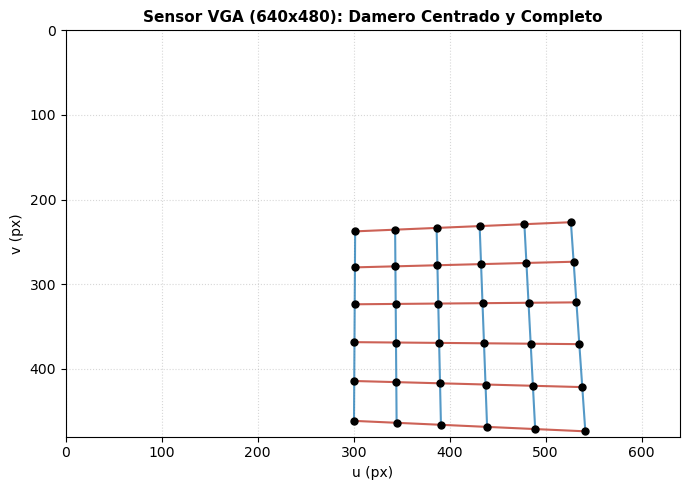

In [6]:
# Asegúrate de tener activo el backend de renderizado de Matplotlib
# %matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as Rot

# ==========================================================================
# 1. CONFIGURACIÓN DE LA CÁMARA SIMPLIFICADA (GROUND TRUTH)
# ==========================================================================
f_true = 600.0          # Focal real (px)
u0, v0 = 320.0, 240.0   # Centro óptico (px)

K_true = np.array([
    [f_true,    0.0,   u0],
    [   0.0, f_true,   v0],
    [   0.0,    0.0,  1.0]
], dtype=np.float64)

# NUEVA POSE OPTIMIZADA: Desplazamiento lateral y alejamiento para centrar el damero
C_true = np.array([80.0, 50.0, -265.0]) 
r_pose = Rot.from_euler('yxz', [15, -10, 0], degrees=True) # Ángulos suavizados
R_true = r_pose.as_matrix()
t_true = -R_true @ C_true

M_true = K_true @ np.hstack([R_true, t_true.reshape(3, 1)])

# ==========================================================================
# 2. CREACIÓN DEL TABLERO DE AJEDREZ 3D (DAMERO)
# ==========================================================================
# Rejilla regular de esquinas de 6x6 en el plano Z_w = 0 (suelo)
xs = np.linspace(0.0, 100.0, 6)
ys = np.linspace(0.0, 100.0, 6)
X, Y = np.meshgrid(xs, ys)
puntos_3d = np.vstack([X.flatten(), Y.flatten(), np.zeros(36), np.ones(36)]).T

# ==========================================================================
# 3. PROYECCIÓN PERSPECTIVA EN EL SENSOR (VGA 640x480)
# ==========================================================================
pts_2d_hom = (M_true @ puntos_3d.T).T
pts_2d = pts_2d_hom[:, :2] / pts_2d_hom[:, 2:3] # División homogénea por Z

# Reestructuramos a una matriz 6x6x2 para trazar las aristas del tablero
corners = pts_2d.reshape(6, 6, 2)

# ==========================================================================
# 4. RENDERIZADO DEL SENSOR VGA COHERENTE
# ==========================================================================
fig, ax = plt.subplots(figsize=(7, 5))

# Dibujamos las líneas de la cuadrícula (Filas en rojo, Columnas en azul)
for i in range(6):
    ax.plot(corners[i, :, 0], corners[i, :, 1], color='#C0392B', alpha=0.8, linewidth=1.5) # Filas
    ax.plot(corners[:, i, 0], corners[:, i, 1], color='#2980B9', alpha=0.8, linewidth=1.5) # Columnas

ax.scatter(pts_2d[:, 0], pts_2d[:, 1], color='black', s=25, zorder=5)
ax.set_xlim(0, 640)
ax.set_ylim(480, 0) # Inversión estándar de píxeles
ax.set_xlabel('u (px)')
ax.set_ylabel('v (px)')
ax.set_title('Sensor VGA (640x480): Damero Centrado y Completo', fontsize=11, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

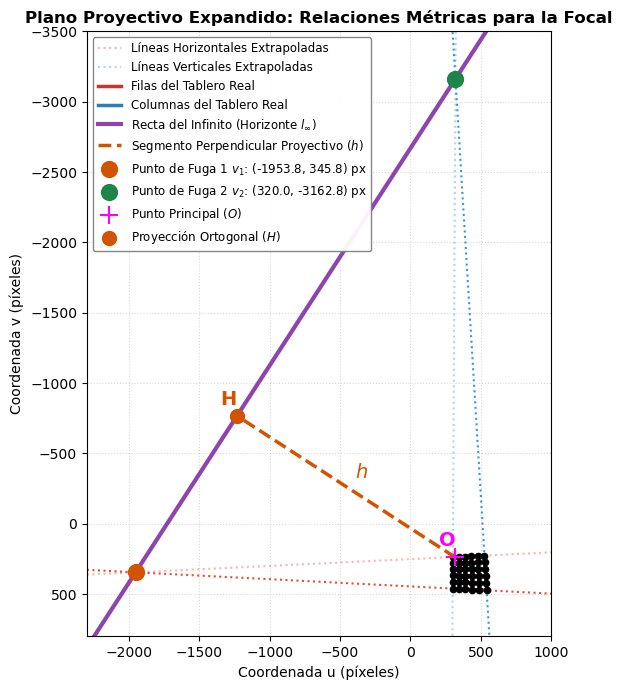

In [7]:
# ==========================================================================
# 1. EXTRACCIÓN DE RECTAS UTILIZANDO PRODUCTOS VECTORIALES (HOMOGÉNEOS)
# ==========================================================================
# Para hallar el punto de fuga 1 (filas): intersecamos Fila 0 y Fila 5
# Convertimos los extremos a coordenadas homogéneas [u, v, 1]
p00 = np.append(corners[0, 0], 1.0)
p05 = np.append(corners[0, -1], 1.0)
p50 = np.append(corners[-1, 0], 1.0)
p55 = np.append(corners[-1, -1], 1.0)

# Ecuación de recta homogénea l = A x B (producto cruz)
l_fila0 = np.cross(p00, p05)
l_fila5 = np.cross(p50, p55)

# Intersección de rectas: punto de fuga v1 = l1 x l2 (y división homogénea por W)
v1_hom = np.cross(l_fila0, l_fila5)
v1 = v1_hom[:2] / v1_hom[2]

# Para hallar el punto de fuga 2 (columnas): intersecamos Columna 0 y Columna 5
p00_col = np.append(corners[0, 0], 1.0)
p50_col = np.append(corners[-1, 0], 1.0)
p05_col = np.append(corners[0, -1], 1.0)
p55_col = np.append(corners[-1, -1], 1.0)

l_col0 = np.cross(p00_col, p50_col)
l_col5 = np.cross(p05_col, p55_col)

# Intersección de rectas: punto de fuga v2 = l1 x l2
v2_hom = np.cross(l_col0, l_col5)
v2 = v2_hom[:2] / v2_hom[2]

# ==========================================================================
# 2. CÁLCULO DE LA RECTA DEL INFINITO (HORIZONTE: l_inf = v1 x v2)
# ==========================================================================
l_inf = np.cross(np.append(v1, 1.0), np.append(v2, 1.0))

# ==========================================================================
# 3. CÁLCULO GEOMÉTRICO DEL PUNTO PRINCIPAL (O) Y SU PROYECCIÓN (H)
# ==========================================================================
O = np.array([u0, v0]) # Punto principal de la cámara

# Vector que define la dirección del horizonte
vec_horizonte = v2 - v1
dir_horizonte = vec_horizonte / np.linalg.norm(vec_horizonte)

# Proyectamos O ortogonalmente sobre la recta que une v1 y v2 para obtener H
vec_v1_a_O = O - v1
H = v1 + np.dot(vec_v1_a_O, dir_horizonte) * dir_horizonte

# ==========================================================================
# 4. VISUALIZACIÓN EN EL ESPACIO PROYECTIVO GIGANTE (ISOMÉTRICA)
# ==========================================================================
fig, ax = plt.subplots(figsize=(11, 7))

# --- ¡NUEVO AJUSTE CRÍTICO! ---
# Forzamos que 1 píxel en X equivalga exactamente a 1 píxel en Y en la pantalla
ax.set_aspect('equal', adjustable='box')

# Rango de extrapolación horizontal para el lienzo gigante
x_extender = np.array([-2300, 1000])

# Función para evaluar la recta homogénea: y = -(a*x + c) / b
def evaluar_recta_homogenea(l, xs):
    return -(l[0] * xs + l[2]) / l[1]

# A. Dibujar líneas de extrapolación punteadas hacia los puntos de fuga
ax.plot(x_extender, evaluar_recta_homogenea(l_fila0, x_extender), color='#E74C3C', linestyle=':', alpha=0.4, label='Líneas Horizontales Extrapoladas')
ax.plot(x_extender, evaluar_recta_homogenea(l_fila5, x_extender), color='#E74C3C', linestyle=':')
ax.plot(x_extender, evaluar_recta_homogenea(l_col0, x_extender), color='#3498DB', linestyle=':', alpha=0.4, label='Líneas Verticales Extrapoladas')
ax.plot(x_extender, evaluar_recta_homogenea(l_col5, x_extender), color='#3498DB', linestyle=':')

# B. DIBUJAR EL TABLERO (DAMERO) REAL ACTIVO (Sólido y limpio en el centro)
for i in range(6):
    ax.plot(corners[i, :, 0], corners[i, :, 1], color='#C0392B', linewidth=2.5, zorder=5,
            label='Filas del Tablero Real' if i == 0 else "")
for i in range(6):
    ax.plot(corners[:, i, 0], corners[:, i, 1], color='#2980B9', linewidth=2.5, zorder=5,
            label='Columnas del Tablero Real' if i == 0 else "")
ax.scatter(pts_2d[:, 0], pts_2d[:, 1], color='black', s=20, zorder=6)

# C. Dibujar la Recta del Infinito (Horizonte l_inf)
ax.plot(x_extender, evaluar_recta_homogenea(l_inf, x_extender), color='#8E44AD', linewidth=3, 
        label='Recta del Infinito (Horizonte $l_{\\infty}$)')

# D. DIBUJAR LA ALTURA ORTOGONAL (Segmento OH que mide h)
# Pasamos las coordenadas X e Y desglosadas por separado de forma limpia
ax.plot([O[0], H[0]], [O[1], H[1]], color='#D35400', linestyle='--', linewidth=2.5, zorder=6,
        label='Segmento Perpendicular Proyectivo ($h$)')

# E. Graficar los puntos de fuga e hitos geométricos con indexación explícita
ax.scatter(v1[0], v1[1], color='#D35400', s=130, zorder=7, 
           label=f'Punto de Fuga 1 $v_1$: ({v1[0]:.1f}, {v1[1]:.1f}) px')
ax.scatter(v2[0], v2[1], color='#1E8449', s=130, zorder=7, 
           label=f'Punto de Fuga 2 $v_2$: ({v2[0]:.1f}, {v2[1]:.1f}) px')

# Añadir los puntos O e H con marcadores bien visibles
ax.scatter(O[0], O[1], color='magenta', marker='+', s=150, zorder=7, label='Punto Principal ($O$)')
ax.scatter(H[0], H[1], color='#D35400', marker='o', s=100, zorder=7, label='Proyección Ortogonal ($H$)')

# F. Añadir etiquetas de texto a los puntos e hitos geométricos
ax.text(O[0] - 120, O[1] - 80, 'O', color='magenta', fontsize=14, fontweight='bold', zorder=8)
ax.text(H[0] - 120, H[1] - 80, 'H', color='#D35400', fontsize=14, fontweight='bold', zorder=8)

# Rotular el segmento h en su punto medio
mid_OH = (O + H) / 2.0
ax.text(mid_OH[0] + 60, mid_OH[1] - 60, '$h$', color='#D35400', fontsize=14, fontweight='bold', style='italic', zorder=8)

# G. Configuración de límites del plano proyectivo gigante
ax.set_xlim(-2300, 1000)
ax.set_ylim(800, -3500) # Inversión del eje Y estándar de imagen
ax.set_xlabel('Coordenada u (píxeles)')
ax.set_ylabel('Coordenada v (píxeles)')
ax.set_title('Plano Proyectivo Expandido: Relaciones Métricas para la Focal', fontsize=12, fontweight='bold')

# H. Leyenda colocada en la esquina superior izquierda
ax.legend(loc='upper left', fontsize=8.5, framealpha=0.95, facecolor='white', edgecolor='gray')
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()


In [8]:
# ==========================================================================
# 1. PROYECCIÓN DEL PUNTO PRINCIPAL (O) SOBRE LA LÍNEA DEL HORIZONTE (l_inf)
# ==========================================================================
O = np.array([u0, v0])

# Vector unitario a lo largo de la recta del horizonte (de v1 a v2)
vec_horizonte = v2 - v1
dir_horizonte = vec_horizonte / np.linalg.norm(vec_horizonte)

# Vector que va desde v1 hasta el punto principal O
vec_v1_a_O = O - v1

# H es la proyección perpendicular del punto principal O sobre el horizonte
H = v1 + np.dot(vec_v1_a_O, dir_horizonte) * dir_horizonte

# ==========================================================================
# 2. CÁLCULO DE MAGNITUDES GEOMÉTRICAS (Distancias en la Imagen)
# ==========================================================================
h = np.linalg.norm(H - O)       # Distancia ortogonal del centro de la imagen al horizonte
x1 = np.linalg.norm(v1 - H)     # Distancia desde la proyección H hasta el punto de fuga 1
x2 = np.linalg.norm(v2 - H)     # Distancia desde la proyección H hasta el punto de fuga 2

# ==========================================================================
# 3. EXTRACCIÓN DE LA FOCAL: f = sqrt(x1 * x2 - h^2)
# ==========================================================================
f_estimada = np.sqrt(x1 * x2 - h**2)

# ==========================================================================
# 4. REPORTE COMPARATIVO FINAL
# ==========================================================================
print("=" * 80)
print("             REPORTE DE CALIBRACIÓN GEOMÉTRICA POR PUNTOS DE FUGA")
print("=" * 80)
print(f"--> Coordenadas Punto Principal O (S Sensor): [{O[0]:.2f}, {O[1]:.2f}] px")
print(f"--> Coordenadas Punto de Fuga v1 (Horizontal): [{v1[0]:.2f}, {v1[1]:.2f}] px")
print(f"--> Coordenadas Punto de Fuga v2 (Vertical):   [{v2[0]:.2f}, {v2[1]:.2f}] px")
print("-" * 80)
print("📐 Magnitudes métricas estimadas sobre el lienzo:")
print(f"  * Distancia al horizonte (h):             {h:.2f} px")
print(f"  * Distancia del corte al punto v1 (x1):   {x1:.2f} px")
print(f"  * Distancia del corte al punto v2 (x2):   {x2:.2f} px")
print("-" * 80)
print(f"🎯 VALOR REAL DE LA FOCAL (f_true):          {f_true:.2f} píxeles")
print(f"🚀 FOCAL ESTIMADA POR DIRECCIONES (f_est):    {f_estimada:.2f} píxeles")
print(f"--> Error absoluto en la focal:              {np.abs(f_true - f_estimada):.2e} píxeles")
print("=" * 80)

             REPORTE DE CALIBRACIÓN GEOMÉTRICA POR PUNTOS DE FUGA
--> Coordenadas Punto Principal O (S Sensor): [320.00, 240.00] px
--> Coordenadas Punto de Fuga v1 (Horizontal): [-1953.77, 345.80] px
--> Coordenadas Punto de Fuga v2 (Vertical):   [320.00, -3162.77] px
--------------------------------------------------------------------------------
📐 Magnitudes métricas estimadas sobre el lienzo:
  * Distancia al horizonte (h):             1850.58 px
  * Distancia del corte al punto v1 (x1):   1325.36 px
  * Distancia del corte al punto v2 (x2):   2855.55 px
--------------------------------------------------------------------------------
🎯 VALOR REAL DE LA FOCAL (f_true):          600.00 píxeles
🚀 FOCAL ESTIMADA POR DIRECCIONES (f_est):    600.00 píxeles
--> Error absoluto en la focal:              7.96e-13 píxeles
